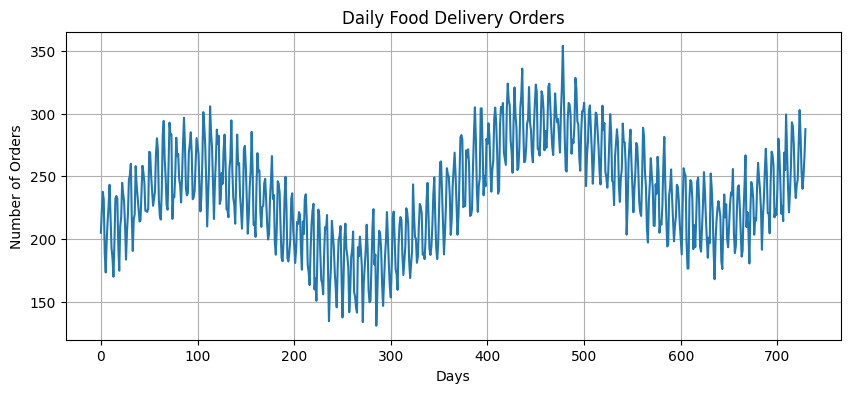

Training data shape: (560, 30, 1)
Testing data shape: (140, 30, 1)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Both models trained successfully!

MODEL PERFORMANCE COMPARISON
       Model     MAE    RMSE  MAPE (%)  Training Time (sec)
0  SimpleRNN  10.689  13.757     4.747                7.205
1       LSTM  20.851  24.321     9.244                4.029


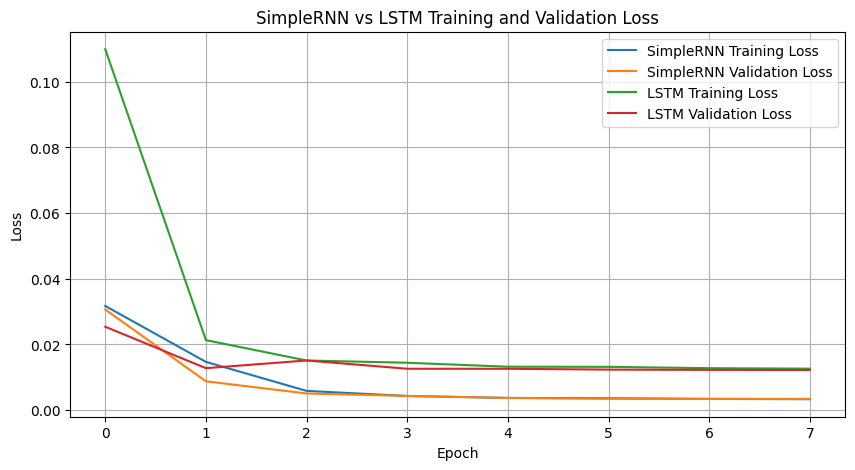

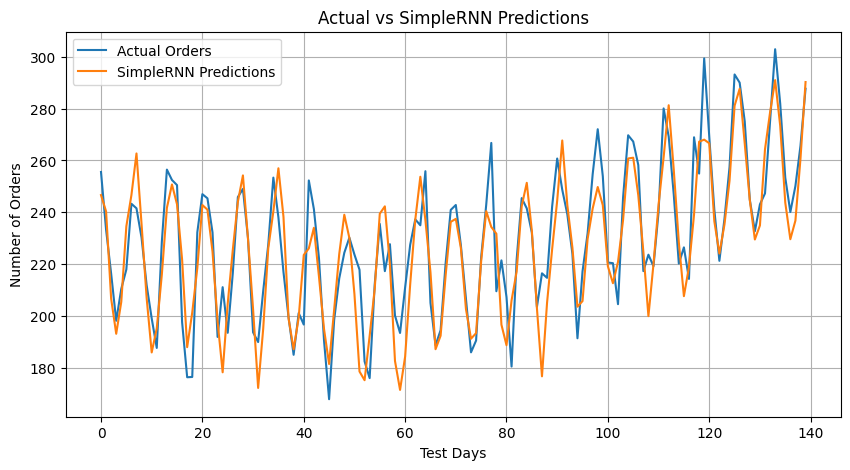

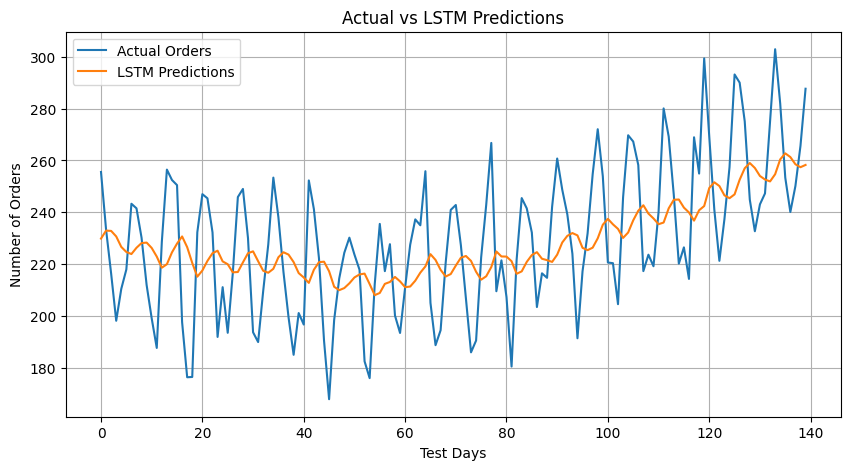


EXPERIMENT 16 COMPLETED SUCCESSFULLY!
SimpleRNN MAE: 10.689
LSTM MAE: 20.851
SimpleRNN RMSE: 13.757
LSTM RMSE: 24.321
SimpleRNN MAPE: 4.747 %
LSTM MAPE: 9.244 %


In [20]:
# EXPERIMENT 16: RNN AND LSTM PERFORMANCE COMPARISON

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense
from tensorflow.keras.utils import set_random_seed

# 1. CREATE SYNTHETIC DAILY FOOD ORDERS DATA

np.random.seed(42)
set_random_seed(42)

days = 730
t = np.arange(days)

orders = (
    200
    + 30 * np.sin(2 * np.pi * t / 7)
    + 50 * np.sin(2 * np.pi * t / 365)
    + 0.1 * t
    + np.random.normal(0, 10, days)
)

orders = orders.astype("float32")

plt.figure(figsize=(10, 4))
plt.plot(orders)
plt.title("Daily Food Delivery Orders")
plt.xlabel("Days")
plt.ylabel("Number of Orders")
plt.grid(True)
plt.show()

# 2. DATA PREPARATION AND SCALING

scaler = MinMaxScaler()

scaled_orders = scaler.fit_transform(
    orders.reshape(-1, 1)
)

# Create 30-day sliding window sequences

X = []
y = []

window_size = 30

for i in range(window_size, len(scaled_orders)):
    X.append(scaled_orders[i-window_size:i])
    y.append(scaled_orders[i])

X = np.array(X)
y = np.array(y)

# Chronological train-test split

split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# 3. CREATE MODEL FUNCTION

def create_model(model_type):

    model = Sequential()

    if model_type == "SimpleRNN":
        model.add(SimpleRNN(32, input_shape=(30, 1)))

    elif model_type == "LSTM":
        model.add(LSTM(32, input_shape=(30, 1)))

    model.add(Dense(16, activation="relu"))
    model.add(Dense(1))

    model.compile(
        optimizer="adam",
        loss="mean_squared_error"
    )

    return model

# 4. TRAIN SIMPLE RNN

rnn_model = create_model("SimpleRNN")

start_time = time.time()

rnn_history = rnn_model.fit(
    X_train,
    y_train,
    epochs=8,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

rnn_time = time.time() - start_time

# 5. TRAIN LSTM

lstm_model = create_model("LSTM")

start_time = time.time()

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    epochs=8,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

lstm_time = time.time() - start_time

print("\nBoth models trained successfully!")

# 6. PREDICTIONS

rnn_pred = rnn_model.predict(X_test, verbose=0)
lstm_pred = lstm_model.predict(X_test, verbose=0)

# Convert predictions back to original scale

rnn_pred = scaler.inverse_transform(rnn_pred)
lstm_pred = scaler.inverse_transform(lstm_pred)

actual = scaler.inverse_transform(y_test)

# 7. CALCULATE PERFORMANCE METRICS

def calculate_metrics(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(mean_squared_error(actual, predicted))

    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    return mae, rmse, mape

rnn_mae, rnn_rmse, rnn_mape = calculate_metrics(
    actual, rnn_pred
)

lstm_mae, lstm_rmse, lstm_mape = calculate_metrics(
    actual, lstm_pred
)

# 8. CREATE COMPARISON TABLE

results = pd.DataFrame({
    "Model": ["SimpleRNN", "LSTM"],
    "MAE": [rnn_mae, lstm_mae],
    "RMSE": [rnn_rmse, lstm_rmse],
    "MAPE (%)": [rnn_mape, lstm_mape],
    "Training Time (sec)": [rnn_time, lstm_time]
})

print("\nMODEL PERFORMANCE COMPARISON")

print(results.round(3))

# 9. TRAINING AND VALIDATION LOSS GRAPH

plt.figure(figsize=(10, 5))

plt.plot(
    rnn_history.history["loss"],
    label="SimpleRNN Training Loss"
)

plt.plot(
    rnn_history.history["val_loss"],
    label="SimpleRNN Validation Loss"
)

plt.plot(
    lstm_history.history["loss"],
    label="LSTM Training Loss"
)

plt.plot(
    lstm_history.history["val_loss"],
    label="LSTM Validation Loss"
)

plt.title("SimpleRNN vs LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# 10. SIMPLE RNN FORECAST GRAPH

plt.figure(figsize=(10, 5))

plt.plot(actual, label="Actual Orders")
plt.plot(rnn_pred, label="SimpleRNN Predictions")

plt.title("Actual vs SimpleRNN Predictions")
plt.xlabel("Test Days")
plt.ylabel("Number of Orders")
plt.legend()
plt.grid(True)
plt.show()

# 11. LSTM FORECAST GRAPH

plt.figure(figsize=(10, 5))

plt.plot(actual, label="Actual Orders")
plt.plot(lstm_pred, label="LSTM Predictions")

plt.title("Actual vs LSTM Predictions")
plt.xlabel("Test Days")
plt.ylabel("Number of Orders")
plt.legend()
plt.grid(True)
plt.show()

# 12. FINAL OUTPUT

print("\nEXPERIMENT 16 COMPLETED SUCCESSFULLY!")
print("SimpleRNN MAE:", round(rnn_mae, 3))
print("LSTM MAE:", round(lstm_mae, 3))
print("SimpleRNN RMSE:", round(rnn_rmse, 3))
print("LSTM RMSE:", round(lstm_rmse, 3))
print("SimpleRNN MAPE:", round(rnn_mape, 3), "%")
print("LSTM MAPE:", round(lstm_mape, 3), "%")